# Salon Experiment & Causal Analysis — A/B Design and Analysis

> **Synthetic data:** The records are generated for this project and are not evidence about real salons or business performance. The analysis uses the recorded assignment groups and does not hard-code the simulated effect.

The **client** is the unit of randomization and analysis. Appointment rows are aggregated to one outcome per assigned client, and clients with no visits remain in the cohort with zero service revenue. The notebook reads, but does not change, the raw CSVs.

## 1. Experiment design, estimand, and assumptions

**Population and randomization:** 24,000 clients in `experiment_assignments.csv`, each assigned once: 12,000 to Control and 12,000 to Treatment.

**Treatment and control:** Compare clients according to their recorded assignment group (intention-to-treat). Assignment, not appointment attendance or treatment take-up, defines group membership.

**Primary outcome:** Each assigned client's total net service revenue in the inclusive experiment window, 2026-09-01 through 2026-10-31. Sum `appointment_revenue` across that client's appointment rows. Clients with no linked appointment in the window receive zero.

**Hypotheses:** H0: mean client-level experiment-window service revenue is equal between assigned groups. H1: the means differ (two-sided). The target estimand is the Treatment-minus-Control difference in mean revenue per randomized client; percentage lift is relative to the Control mean.

**Guardrails / secondary outcomes:** client-level appointment volume, completed/cancelled/no-show outcomes, experiment-period engagement and repeat completion, and product revenue per randomized client. These are secondary and should not replace the primary outcome.

**Key assumptions and caveats:** assignment is implemented as recorded; each client has one assignment; outcomes are measured consistently; clients do not affect one another's outcomes; and the assigned clients are the analysis population. The policy simulation starts 2026-07-01, so policy exposure overlaps the A/B window in September–October. Randomization supports an average assignment comparison within this generated policy mix, but this notebook does not isolate a policy effect. Four synthetic regions also limit policy-level inference. The simulated dataset is not a real-world experiment.

## 2. Load data and validate the analysis cohort

The setup locates the project root from either the root or `notebooks/` directory. It loads the tables needed for the cohort, checks their schemas and dates, and stops if the assignment checks fail.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import TTestIndPower

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (root for root in candidate_roots if (root / "data" / "raw").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/raw. Start Jupyter in the project root or notebooks/."
    )
RAW_DIR = PROJECT_ROOT / "data" / "raw"

EXPECTED_FILES = [
    "appointments.csv",
    "clients.csv",
    "outlets.csv",
    "stylists.csv",
    "services.csv",
    "products.csv",
    "product_sales.csv",
    "experiment_assignments.csv",
    "did_outlet_policy.csv",
    "data_dictionary.csv",
]
missing_files = [name for name in EXPECTED_FILES if not (RAW_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Required raw CSVs are missing: {missing_files}")

tables = {name: pd.read_csv(RAW_DIR / name) for name in EXPECTED_FILES}
appointments = tables["appointments.csv"]
clients = tables["clients.csv"]
assignments = tables["experiment_assignments.csv"]
product_sales = tables["product_sales.csv"]
outlets = tables["outlets.csv"]
policy = tables["did_outlet_policy.csv"]

appointments["appointment_date"] = pd.to_datetime(
    appointments["appointment_date"], errors="coerce"
)
clients["signup_date"] = pd.to_datetime(clients["signup_date"], errors="coerce")
assignments["assigned_at"] = pd.to_datetime(assignments["assigned_at"], errors="coerce")
assignments["experiment_start_date"] = pd.to_datetime(
    assignments["experiment_start_date"], errors="coerce"
)
assignments["experiment_end_date"] = pd.to_datetime(
    assignments["experiment_end_date"], errors="coerce"
)
product_sales["sale_date"] = pd.to_datetime(product_sales["sale_date"], errors="coerce")
policy["policy_start_date"] = pd.to_datetime(policy["policy_start_date"], errors="coerce")

required_columns = {
    "appointments.csv": {
        "appointment_id", "client_id", "appointment_date", "appointment_status",
        "appointment_revenue", "outlet_id",
    },
    "clients.csv": {"client_id", "signup_date", "retention_segment", "preferred_outlet_id"},
    "experiment_assignments.csv": {
        "client_id", "assignment_group", "assigned_at",
        "experiment_start_date", "experiment_end_date",
    },
    "product_sales.csv": {"client_id", "sale_date", "product_revenue"},
    "outlets.csv": {"outlet_id", "region"},
    "did_outlet_policy.csv": {"outlet_id", "region", "policy_group", "policy_start_date"},
}
for file_name, required in required_columns.items():
    absent = required - set(tables[file_name].columns)
    if absent:
        raise ValueError(f"{file_name} is missing required columns: {sorted(absent)}")

EXPERIMENT_START = pd.Timestamp("2026-09-01")
EXPERIMENT_END = pd.Timestamp("2026-10-31")
ASSIGNMENT_DATE = pd.Timestamp("2026-08-15")
BASELINE_START = pd.Timestamp("2026-05-01")
BASELINE_END_EXCLUSIVE = pd.Timestamp("2026-07-01")

assert assignments["client_id"].notna().all(), "Assignment client IDs must be present."
assert assignments["client_id"].is_unique, "Each client must have one assignment."
assert assignments["assignment_group"].isin(["Control", "Treatment"]).all()
assert assignments["client_id"].nunique() == 24_000
group_counts = assignments["assignment_group"].value_counts()
assert group_counts.get("Control", 0) == 12_000
assert group_counts.get("Treatment", 0) == 12_000
assert assignments["assigned_at"].eq(ASSIGNMENT_DATE).all()
assert assignments["experiment_start_date"].eq(EXPERIMENT_START).all()
assert assignments["experiment_end_date"].eq(EXPERIMENT_END).all()
assert clients["client_id"].is_unique
assert set(assignments["client_id"]) == set(clients["client_id"])
assert clients["signup_date"].le(ASSIGNMENT_DATE).all()

print(f"Project root: {PROJECT_ROOT}")
print(f"Loaded {len(tables)} raw CSVs (read-only).")
print(f"Validated {len(assignments):,} unique randomized clients: {group_counts.to_dict()}.")
print(f"Experiment window: {EXPERIMENT_START.date()} through {EXPERIMENT_END.date()}.")

Project root: C:\Users\HP\Desktop\intrenship\salon-causal-analysis
Loaded 10 raw CSVs (read-only).
Validated 24,000 unique randomized clients: {'Treatment': 12000, 'Control': 12000}.
Experiment window: 2026-09-01 through 2026-10-31.


## 3. Sample ratio mismatch (SRM)

An SRM check compares observed assignment counts with the expected 1:1 allocation using a chi-square goodness-of-fit test. It is a data-quality diagnostic, not a treatment-effect test. A small p-value would flag a possible assignment, logging, or cohort-construction problem; it would not explain the cause.

In [2]:
observed_counts = assignments["assignment_group"].value_counts().reindex(
    ["Control", "Treatment"], fill_value=0
)
expected_counts = np.repeat(len(assignments) / 2, 2)
srm_statistic, srm_p_value = stats.chisquare(
    f_obs=observed_counts.to_numpy(), f_exp=expected_counts
)
srm_result = pd.DataFrame(
    {
        "observed": observed_counts,
        "expected_under_1_to_1": expected_counts,
    }
)
display(srm_result)
print(f"SRM chi-square statistic: {srm_statistic:.4f}")
print(f"SRM p-value: {srm_p_value:.6g}")
print("SRM diagnostic:", "FLAG (p < 0.001)" if srm_p_value < 0.001 else "no SRM flag at p < 0.001")

,observed,expected_under_1_to_1
assignment_group,,
Control,12000,12000.0
Treatment,12000,12000.0


SRM chi-square statistic: 0.0000
SRM p-value: 1
SRM diagnostic: no SRM flag at p < 0.001


## 4. Client-level baseline balance

Baseline covariates use information recorded before the experiment. May–June 2026 is the two-month pre-policy baseline. Every assigned client remains in the table; clients without baseline appointments have zero counts and revenue. Standardized mean differences (SMDs) summarize balance more usefully than a set of baseline significance tests: chance differences are expected, and p-values do not certify that randomization was valid. Categorical fields are represented by level-specific indicators.

In [3]:
baseline_appointments = appointments.loc[
    appointments["appointment_date"].ge(BASELINE_START)
    & appointments["appointment_date"].lt(BASELINE_END_EXCLUSIVE)
    & appointments["client_id"].notna()
].copy()
baseline_appointment_metrics = baseline_appointments.groupby("client_id").agg(
    baseline_appointments=("appointment_id", "size"),
    baseline_completed=("appointment_status", lambda values: values.eq("Completed").sum()),
    baseline_service_revenue=("appointment_revenue", "sum"),
)

baseline_sales = product_sales.loc[
    product_sales["sale_date"].ge(BASELINE_START)
    & product_sales["sale_date"].lt(BASELINE_END_EXCLUSIVE)
    & product_sales["client_id"].notna()
]
baseline_product_revenue = baseline_sales.groupby("client_id")["product_revenue"].sum()
baseline_product_revenue.name = "baseline_product_revenue"

region_by_outlet = outlets.set_index("outlet_id")["region"]
baseline = (
    assignments[["client_id", "assignment_group"]]
    .merge(
        clients[["client_id", "signup_date", "retention_segment", "preferred_outlet_id"]],
        on="client_id",
        how="left",
        validate="one_to_one",
    )
    .merge(baseline_appointment_metrics, on="client_id", how="left", validate="one_to_one")
    .merge(baseline_product_revenue, on="client_id", how="left", validate="one_to_one")
)
for column in [
    "baseline_appointments", "baseline_completed",
    "baseline_service_revenue", "baseline_product_revenue",
]:
    baseline[column] = baseline[column].fillna(0)
baseline["signup_age_days_at_assignment"] = (
    ASSIGNMENT_DATE - baseline["signup_date"]
).dt.days
baseline["preferred_region"] = baseline["preferred_outlet_id"].map(region_by_outlet)

numeric_baseline = [
    "signup_age_days_at_assignment",
    "baseline_appointments",
    "baseline_completed",
    "baseline_service_revenue",
    "baseline_product_revenue",
]

def numeric_smd(treatment, control):
    treatment = pd.to_numeric(treatment, errors="coerce").dropna()
    control = pd.to_numeric(control, errors="coerce").dropna()
    pooled_sd = np.sqrt((treatment.var(ddof=1) + control.var(ddof=1)) / 2)
    if pooled_sd == 0:
        return 0.0 if treatment.mean() == control.mean() else np.inf
    return (treatment.mean() - control.mean()) / pooled_sd

def categorical_smd_rows(frame, column):
    values = frame[column].fillna("Missing").astype(str)
    rows = []
    for level in sorted(values.unique()):
        indicator = values.eq(level)
        p_treatment = indicator[frame["assignment_group"].eq("Treatment")].mean()
        p_control = indicator[frame["assignment_group"].eq("Control")].mean()
        pooled_sd = np.sqrt(
            (p_treatment * (1 - p_treatment) + p_control * (1 - p_control)) / 2
        )
        smd = 0.0 if pooled_sd == 0 and p_treatment == p_control else (
            (p_treatment - p_control) / pooled_sd if pooled_sd else np.inf
        )
        rows.append(
            {"feature": f"{column}={level}", "treatment": p_treatment,
             "control": p_control, "smd": smd}
        )
    return rows

balance_rows = []
for feature in numeric_baseline:
    treatment_values = baseline.loc[
        baseline["assignment_group"].eq("Treatment"), feature
    ]
    control_values = baseline.loc[
        baseline["assignment_group"].eq("Control"), feature
    ]
    balance_rows.append(
        {
            "feature": feature,
            "treatment": treatment_values.mean(),
            "control": control_values.mean(),
            "smd": numeric_smd(treatment_values, control_values),
        }
    )
for feature in ["retention_segment", "preferred_region"]:
    balance_rows.extend(categorical_smd_rows(baseline, feature))
balance_table = pd.DataFrame(balance_rows)
balance_table["absolute_smd"] = balance_table["smd"].abs()
display(balance_table.sort_values("absolute_smd", ascending=False).round(3))
print(
    "Rule of thumb only: absolute SMD below 0.10 is often considered a small "
    "descriptive imbalance; it is not a pass/fail validity test."
)

,feature,treatment,control,smd,absolute_smd
1,baseline_appointments,1.307,1.248,0.027,0.027
3,baseline_service_revenue,70.602,67.344,0.026,0.026
2,baseline_completed,1.156,1.107,0.025,0.025
4,baseline_product_revenue,8.043,7.696,0.019,0.019
7,retention_segment=Occasional,0.250,0.258,-0.018,0.018
6,retention_segment=Loyal,0.203,0.196,0.018,0.018
0,signup_age_days_at_assignment,370.312,373.007,-0.015,0.015
9,preferred_region=East,0.234,0.230,0.010,0.010
5,retention_segment=At-risk,0.151,0.147,0.010,0.010
12,preferred_region=West,0.270,0.273,-0.007,0.007


Rule of thumb only: absolute SMD below 0.10 is often considered a small descriptive imbalance; it is not a pass/fail validity test.


## 5. Build one intention-to-treat row per randomized client

Aggregate appointments and identified product sales during the exact experiment dates, then left-join those sums onto the full assignment roster. This construction guarantees that no-appointment clients remain present with zero revenue and zero event counts. Anonymous walk-in product sales cannot be linked to a randomized client and are excluded from client-level product revenue; their total is reported separately.

In [4]:
experiment_appointments = appointments.loc[
    appointments["appointment_date"].ge(EXPERIMENT_START)
    & appointments["appointment_date"].le(EXPERIMENT_END)
].copy()
linked_experiment_appointments = experiment_appointments.loc[
    experiment_appointments["client_id"].notna()
]
appointment_client_metrics = linked_experiment_appointments.groupby("client_id").agg(
    appointment_count=("appointment_id", "size"),
    completed_count=("appointment_status", lambda values: values.eq("Completed").sum()),
    cancelled_count=("appointment_status", lambda values: values.eq("Cancelled").sum()),
    no_show_count=("appointment_status", lambda values: values.eq("No-show").sum()),
    service_revenue=("appointment_revenue", "sum"),
)

experiment_sales = product_sales.loc[
    product_sales["sale_date"].ge(EXPERIMENT_START)
    & product_sales["sale_date"].le(EXPERIMENT_END)
].copy()
anonymous_product_revenue = experiment_sales.loc[
    experiment_sales["client_id"].isna(), "product_revenue"
].sum()
client_product_revenue = (
    experiment_sales.loc[experiment_sales["client_id"].notna()]
    .groupby("client_id")["product_revenue"]
    .sum()
    .rename("product_revenue")
)

itt = (
    assignments[["client_id", "assignment_group"]]
    .merge(appointment_client_metrics, on="client_id", how="left", validate="one_to_one")
    .merge(client_product_revenue, on="client_id", how="left", validate="one_to_one")
)
count_columns = [
    "appointment_count", "completed_count", "cancelled_count", "no_show_count"
]
for column in count_columns + ["service_revenue", "product_revenue"]:
    itt[column] = itt[column].fillna(0)
itt[count_columns] = itt[count_columns].astype(int)
itt["completed_share_per_client"] = np.divide(
    itt["completed_count"], itt["appointment_count"],
    out=np.zeros(len(itt), dtype=float), where=itt["appointment_count"].to_numpy() > 0,
)
itt["cancelled_share_per_client"] = np.divide(
    itt["cancelled_count"], itt["appointment_count"],
    out=np.zeros(len(itt), dtype=float), where=itt["appointment_count"].to_numpy() > 0,
)
itt["no_show_share_per_client"] = np.divide(
    itt["no_show_count"], itt["appointment_count"],
    out=np.zeros(len(itt), dtype=float), where=itt["appointment_count"].to_numpy() > 0,
)
itt["any_completed"] = itt["completed_count"].gt(0).astype(int)
itt["any_cancelled"] = itt["cancelled_count"].gt(0).astype(int)
itt["any_no_show"] = itt["no_show_count"].gt(0).astype(int)
itt["period_engaged"] = itt["any_completed"]
itt["repeat_completed"] = itt["completed_count"].ge(2).astype(int)

assert len(itt) == len(assignments) == 24_000
assert itt["client_id"].is_unique
assert itt["service_revenue"].ge(0).all()
print(f"ITT analysis rows: {len(itt):,} unique randomized clients.")
print(f"Clients with zero experiment-period appointments: {(itt['appointment_count'] == 0).sum():,}")
print(f"Clients with zero experiment-period service revenue: {(itt['service_revenue'] == 0).sum():,}")
print(f"Anonymous product revenue excluded from client outcomes: {anonymous_product_revenue:,.2f}.")
display(itt.groupby("assignment_group").agg(
    clients=("client_id", "nunique"),
    clients_with_no_visits=("appointment_count", lambda values: values.eq(0).sum()),
    mean_service_revenue=("service_revenue", "mean"),
))

ITT analysis rows: 24,000 unique randomized clients.
Clients with zero experiment-period appointments: 18,277
Clients with zero experiment-period service revenue: 18,384
Anonymous product revenue excluded from client outcomes: 27,985.55.


,clients,clients_with_no_visits,mean_service_revenue
assignment_group,,,
Control,12000,9202,65.022713
Treatment,12000,9075,70.850524


## 6. Primary metric: client-level service revenue ITT

The estimate is Treatment mean minus Control mean, in synthetic currency units per randomized client. Welch's two-sample t-test does not assume equal group variances. Its 95% confidence interval uses the Welch-Satterthwaite degrees of freedom. A separate percentile bootstrap resamples clients independently within their assigned groups; it never resamples appointment rows. The bootstrap seed and iteration count are fixed for reproducibility.

In [5]:
ALPHA = 0.05
BOOTSTRAP_REPLICATES = 3_000
ANALYSIS_SEED = 42

def welch_mean_comparison(treatment, control, alpha=ALPHA):
    treatment = np.asarray(treatment, dtype=float)
    control = np.asarray(control, dtype=float)
    n_t, n_c = len(treatment), len(control)
    mean_difference = treatment.mean() - control.mean()
    variance_t = treatment.var(ddof=1)
    variance_c = control.var(ddof=1)
    standard_error = np.sqrt(variance_t / n_t + variance_c / n_c)
    numerator = (variance_t / n_t + variance_c / n_c) ** 2
    denominator = (
        (variance_t / n_t) ** 2 / (n_t - 1)
        + (variance_c / n_c) ** 2 / (n_c - 1)
    )
    degrees_freedom = numerator / denominator if denominator > 0 else np.inf
    critical_value = stats.t.ppf(1 - alpha / 2, degrees_freedom)
    ci_low = mean_difference - critical_value * standard_error
    ci_high = mean_difference + critical_value * standard_error
    test = stats.ttest_ind(treatment, control, equal_var=False, alternative="two-sided")
    control_mean = control.mean()
    percentage_lift = (
        100 * mean_difference / control_mean if control_mean != 0 else np.nan
    )
    return {
        "n_treatment": n_t,
        "n_control": n_c,
        "mean_treatment": treatment.mean(),
        "mean_control": control_mean,
        "difference_treatment_minus_control": mean_difference,
        "welch_ci_low": ci_low,
        "welch_ci_high": ci_high,
        "welch_t": test.statistic,
        "welch_df": degrees_freedom,
        "welch_p_value": test.pvalue,
        "percentage_lift": percentage_lift,
    }

def bootstrap_mean_difference(
    treatment, control, n_resamples=BOOTSTRAP_REPLICATES,
    confidence=0.95, seed=ANALYSIS_SEED, batch_size=100,
):
    treatment = np.asarray(treatment, dtype=float)
    control = np.asarray(control, dtype=float)
    rng = np.random.default_rng(seed)
    differences = np.empty(n_resamples, dtype=float)
    for start in range(0, n_resamples, batch_size):
        size = min(batch_size, n_resamples - start)
        t_indices = rng.integers(0, len(treatment), size=(size, len(treatment)))
        c_indices = rng.integers(0, len(control), size=(size, len(control)))
        differences[start:start + size] = (
            treatment[t_indices].mean(axis=1) - control[c_indices].mean(axis=1)
        )
    tail = (1 - confidence) / 2
    return (
        float(np.quantile(differences, tail)),
        float(np.quantile(differences, 1 - tail)),
        differences,
    )

treatment_revenue = itt.loc[
    itt["assignment_group"].eq("Treatment"), "service_revenue"
].to_numpy()
control_revenue = itt.loc[
    itt["assignment_group"].eq("Control"), "service_revenue"
].to_numpy()
primary_result = welch_mean_comparison(treatment_revenue, control_revenue)
bootstrap_low, bootstrap_high, bootstrap_differences = bootstrap_mean_difference(
    treatment_revenue, control_revenue
)
primary_result["bootstrap_ci_low"] = bootstrap_low
primary_result["bootstrap_ci_high"] = bootstrap_high
primary_table = pd.DataFrame([primary_result]).T.rename(columns={0: "estimate"})
display(primary_table.round(4))
print(
    f"Primary estimate: {primary_result['difference_treatment_minus_control']:,.2f} "
    f"per randomized client; percentage lift: {primary_result['percentage_lift']:.2f}%."
)
print(
    f"Welch 95% CI: [{primary_result['welch_ci_low']:,.2f}, "
    f"{primary_result['welch_ci_high']:,.2f}]"
)
print(f"Bootstrap percentile 95% CI: [{bootstrap_low:,.2f}, {bootstrap_high:,.2f}]")
print(f"Two-sided Welch p-value: {primary_result['welch_p_value']:.6g}")

,estimate
n_treatment,12000.0000
n_control,12000.0000
mean_treatment,70.8505
mean_control,65.0227
difference_treatment_minus_control,5.8278
welch_ci_low,1.5486
welch_ci_high,10.1070
welch_t,2.6694
welch_df,23934.0596
welch_p_value,0.0076


Primary estimate: 5.83 per randomized client; percentage lift: 8.96%.
Welch 95% CI: [1.55, 10.11]
Bootstrap percentile 95% CI: [1.33, 10.20]
Two-sided Welch p-value: 0.00760408


## 7. Power and sample-size planning from baseline client data

For planning only, define the MDE as **0.10 baseline standard deviations** of the client-level May–June service-revenue outcome. This is a conventional small standardized-effect benchmark; it is not a business-derived threshold or an assumed/known experiment effect. We use a two-sided alpha of 0.05, target power of 0.80, and equal allocation. The baseline outcome includes every assigned client with zero revenue when no linked appointments occurred.

The two-sample t-test power calculation is an approximation: revenue is zero-inflated and skewed, and the calculation assumes a standardized mean difference framework. It should be treated as planning guidance, not a guarantee of achieved power. Replace the illustrative 0.10-SD threshold with a stakeholder-defined minimum worthwhile effect for a real design.

In [6]:
baseline_sd = baseline["baseline_service_revenue"].std(ddof=1)
baseline_mean = baseline["baseline_service_revenue"].mean()
analysis = TTestIndPower()
target_power = 0.80
planning_effect_size = 0.10

if not np.isfinite(baseline_sd) or baseline_sd <= 0:
    raise ValueError("Baseline service-revenue standard deviation must be positive.")

planning_mde_currency = planning_effect_size * baseline_sd
required_n_per_group = analysis.solve_power(
    effect_size=planning_effect_size,
    power=target_power,
    alpha=ALPHA,
    ratio=1.0,
    alternative="two-sided",
)
observed_mde_effect_size = analysis.solve_power(
    effect_size=None,
    nobs1=group_counts.get("Treatment", 0),
    alpha=ALPHA,
    power=target_power,
    ratio=1.0,
    alternative="two-sided",
)
observed_mde_currency = observed_mde_effect_size * baseline_sd

planning_sensitivity = []
for effect_size in [0.10, 0.20, 0.30]:
    needed = analysis.solve_power(
        effect_size=effect_size, power=target_power, alpha=ALPHA,
        ratio=1.0, alternative="two-sided",
    )
    planning_sensitivity.append(
        {"standardized_effect": effect_size,
         "MDE_in_baseline_currency": effect_size * baseline_sd,
         "required_n_per_group": int(np.ceil(needed))}
    )

power_summary = pd.DataFrame(
    [
        {"quantity": "Baseline mean service revenue per client (May-June)", "value": baseline_mean},
        {"quantity": "Baseline client-level standard deviation", "value": baseline_sd},
        {"quantity": "Planning MDE (0.10 SD), currency/client", "value": planning_mde_currency},
        {"quantity": "Required clients per group at 80% power", "value": required_n_per_group},
        {"quantity": "Observed clients per group", "value": group_counts.get("Treatment", 0)},
        {"quantity": "Approximate detectable effect at observed n (SD)", "value": observed_mde_effect_size},
        {"quantity": "Approximate detectable effect at observed n, currency/client", "value": observed_mde_currency},
    ]
)
display(power_summary.round(3))
display(pd.DataFrame(planning_sensitivity).round(3))

,quantity,value
0,Baseline mean service revenue per client (May-...,68.973
1,Baseline client-level standard deviation,125.690
2,"Planning MDE (0.10 SD), currency/client",12.569
3,Required clients per group at 80% power,1570.733
4,Observed clients per group,12000.000
5,Approximate detectable effect at observed n (SD),0.036
6,"Approximate detectable effect at observed n, c...",4.546


,standardized_effect,MDE_in_baseline_currency,required_n_per_group
0,0.1,12.569,1571
1,0.2,25.138,394
2,0.3,37.707,176


## 8. Secondary and guardrail outcomes

All metrics below are aggregated to one row per randomized client and include clients with no appointments. `period_engaged` / retention means at least one completed experiment-period appointment; `repeat_completed` means at least two completed appointments during the period. These are operational, short-window definitions—not long-term customer retention. Per-client status shares are set to zero for clients with no appointments, so their group means describe event share averaged over the full randomized cohort. Product revenue excludes unlinked walk-in sales as noted above.

Secondary comparisons are descriptive and not multiplicity-adjusted. Do not treat their intervals or patterns as independent confirmation of the primary outcome.

In [7]:
SECONDARY_METRICS = {
    "Appointment rows per client": "appointment_count",
    "Completed appointment share per client": "completed_share_per_client",
    "Cancelled appointment share per client": "cancelled_share_per_client",
    "No-show appointment share per client": "no_show_share_per_client",
    "Any completed appointment (client-level)": "any_completed",
    "Any cancellation (client-level)": "any_cancelled",
    "Any no-show (client-level)": "any_no_show",
    "Period engaged / retention proxy": "period_engaged",
    "Repeat completed appointments (2+)": "repeat_completed",
    "Product revenue per randomized client": "product_revenue",
}

secondary_rows = []
for label, column in SECONDARY_METRICS.items():
    treatment_values = itt.loc[itt["assignment_group"].eq("Treatment"), column].to_numpy()
    control_values = itt.loc[itt["assignment_group"].eq("Control"), column].to_numpy()
    result = welch_mean_comparison(treatment_values, control_values)
    secondary_rows.append(
        {
            "metric": label,
            "treatment_n": result["n_treatment"],
            "control_n": result["n_control"],
            "treatment_mean": result["mean_treatment"],
            "control_mean": result["mean_control"],
            "difference_T_minus_C": result["difference_treatment_minus_control"],
            "welch_95ci_low": result["welch_ci_low"],
            "welch_95ci_high": result["welch_ci_high"],
        }
    )
secondary_results = pd.DataFrame(secondary_rows).set_index("metric")
display(secondary_results.round(4))
print("For binary metrics, multiply group means and differences by 100 for percentage points.")

,treatment_n,control_n,treatment_mean,control_mean,difference_T_minus_C,welch_95ci_low,welch_95ci_high
metric,,,,,,,
Appointment rows per client,12000,12000,1.2178,1.1803,0.0374,-0.0348,0.1096
Completed appointment share per client,12000,12000,0.2158,0.2078,0.0079,-0.0019,0.0178
Cancelled appointment share per client,12000,12000,0.0175,0.0158,0.0017,-0.0003,0.0038
No-show appointment share per client,12000,12000,0.0105,0.0096,0.0009,-0.0007,0.0025
Any completed appointment (client-level),12000,12000,0.2388,0.2292,0.0095,-0.0012,0.0202
Any cancellation (client-level),12000,12000,0.0695,0.0648,0.0047,-0.0017,0.0110
Any no-show (client-level),12000,12000,0.0433,0.0422,0.0011,-0.0040,0.0062
Period engaged / retention proxy,12000,12000,0.2388,0.2292,0.0095,-0.0012,0.0202
Repeat completed appointments (2+),12000,12000,0.1991,0.1928,0.0063,-0.0038,0.0163


For binary metrics, multiply group means and differences by 100 for percentage points.


## 9. Visualizations

Plots show client-level outcomes and uncertainty. The primary outcome has a long-tailed distribution, so the first chart uses `log1p` only for visualization; all estimates above remain on the original currency scale. The bootstrap distribution is centered on resampled client-level mean differences.

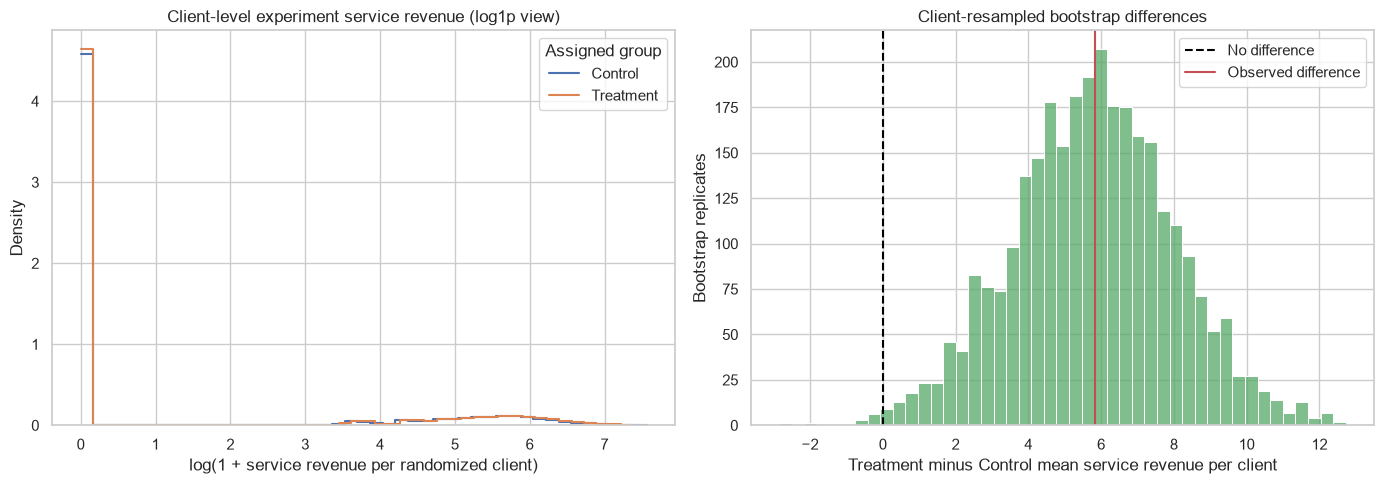

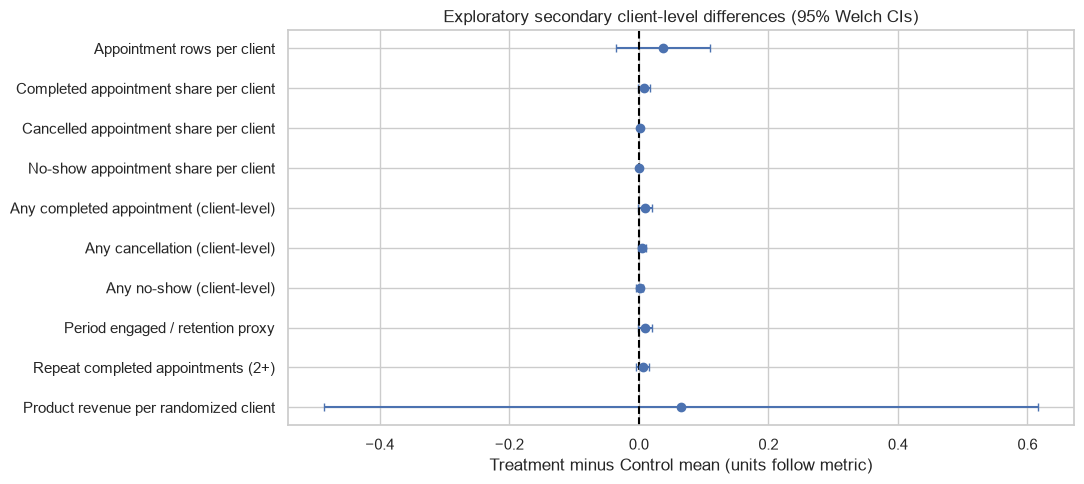

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for group, color in zip(["Control", "Treatment"], sns.color_palette()[:2]):
    values = itt.loc[itt["assignment_group"].eq(group), "service_revenue"]
    sns.histplot(np.log1p(values), bins=45, stat="density", element="step",
                 fill=False, label=group, color=color, ax=axes[0])
axes[0].set(
    title="Client-level experiment service revenue (log1p view)",
    xlabel="log(1 + service revenue per randomized client)",
    ylabel="Density",
)
axes[0].legend(title="Assigned group")

sns.histplot(bootstrap_differences, bins=45, color=sns.color_palette()[2], ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", label="No difference")
axes[1].axvline(primary_result["difference_treatment_minus_control"],
                color=sns.color_palette()[3], label="Observed difference")
axes[1].set(
    title="Client-resampled bootstrap differences",
    xlabel="Treatment minus Control mean service revenue per client",
    ylabel="Bootstrap replicates",
)
axes[1].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
plot_results = secondary_results.reset_index()
plot_results["difference_pct_points_or_currency"] = plot_results["difference_T_minus_C"]
ax.errorbar(
    plot_results["difference_T_minus_C"],
    np.arange(len(plot_results)),
    xerr=[
        plot_results["difference_T_minus_C"] - plot_results["welch_95ci_low"],
        plot_results["welch_95ci_high"] - plot_results["difference_T_minus_C"],
    ],
    fmt="o",
    capsize=3,
)
ax.axvline(0, color="black", linestyle="--")
ax.set_yticks(np.arange(len(plot_results)))
ax.set_yticklabels(plot_results["metric"])
ax.invert_yaxis()
ax.set(title="Exploratory secondary client-level differences (95% Welch CIs)",
       xlabel="Treatment minus Control mean (units follow metric)")
plt.tight_layout()
plt.show()

## 10. Exploratory segment analysis

These are exploratory client-level ITT contrasts by pre-existing retention segment and preferred outlet region. Each client is still one analysis row. Segment sample sizes and differences are shown to highlight uncertainty and potential sparse groups. No multiplicity correction is applied, subgroup results are not confirmatory, and no segment-based decision is recommended.

,segment_variable,segment,treatment_n,control_n,treatment_mean,control_mean,difference_T_minus_C,percentage_lift
0,retention_segment,At-risk,1812,1769,12.307,13.061,-0.754,-5.770
1,retention_segment,Loyal,2440,2353,160.301,151.466,8.835,5.833
2,retention_segment,Occasional,3001,3096,30.812,29.489,1.323,4.488
3,retention_segment,Regular,4747,4782,72.531,64.716,7.815,12.076
4,preferred_region,East,2812,2759,65.457,57.413,8.044,14.010
5,preferred_region,North,3242,3266,75.441,67.146,8.294,12.353
6,preferred_region,South,2711,2702,73.621,67.733,5.888,8.693
7,preferred_region,West,3235,3273,68.617,67.080,1.536,2.290


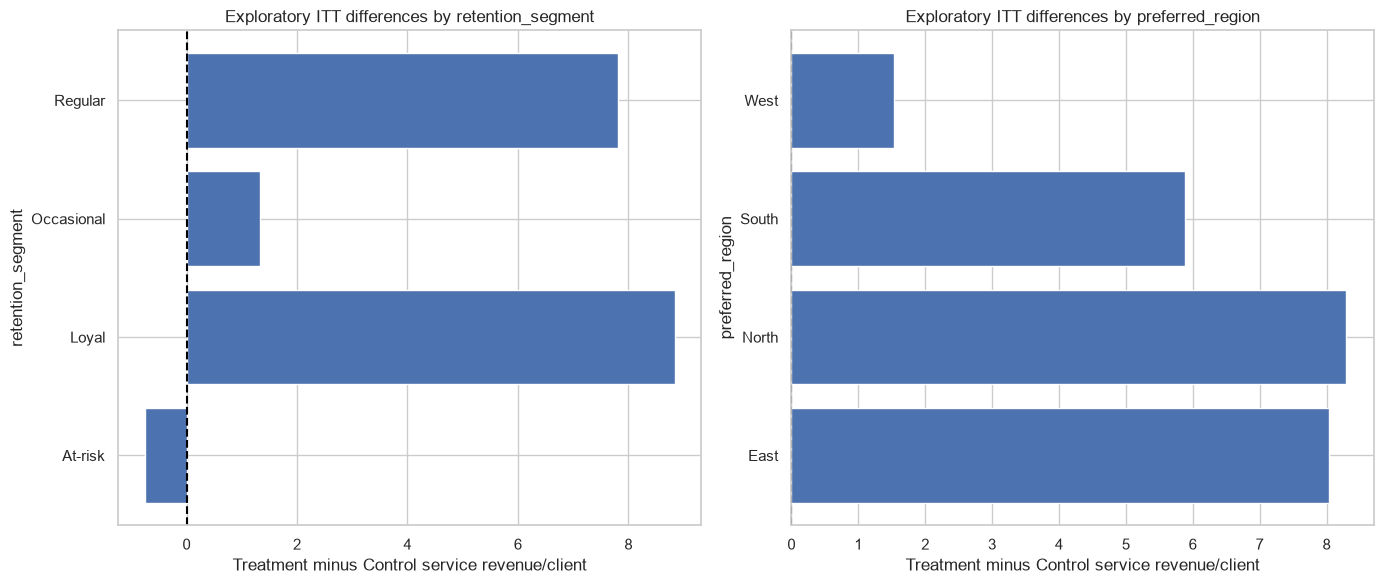

In [9]:
segment_data = itt.merge(
    clients[["client_id", "retention_segment", "preferred_outlet_id"]],
    on="client_id", how="left", validate="one_to_one",
)
segment_data["preferred_region"] = segment_data["preferred_outlet_id"].map(region_by_outlet)

segment_rows = []
for segment_variable in ["retention_segment", "preferred_region"]:
    for segment_value, frame in segment_data.groupby(segment_variable, dropna=False):
        treatment_values = frame.loc[
            frame["assignment_group"].eq("Treatment"), "service_revenue"
        ]
        control_values = frame.loc[
            frame["assignment_group"].eq("Control"), "service_revenue"
        ]
        if treatment_values.empty or control_values.empty:
            continue
        control_mean = control_values.mean()
        difference = treatment_values.mean() - control_mean
        segment_rows.append(
            {
                "segment_variable": segment_variable,
                "segment": str(segment_value),
                "treatment_n": len(treatment_values),
                "control_n": len(control_values),
                "treatment_mean": treatment_values.mean(),
                "control_mean": control_mean,
                "difference_T_minus_C": difference,
                "percentage_lift": 100 * difference / control_mean if control_mean else np.nan,
            }
        )
segment_results = pd.DataFrame(segment_rows)
display(segment_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, variable in zip(axes, ["retention_segment", "preferred_region"]):
    subset = segment_results.loc[segment_results["segment_variable"].eq(variable)]
    ax.barh(subset["segment"], subset["difference_T_minus_C"])
    ax.axvline(0, color="black", linestyle="--")
    ax.set(title=f"Exploratory ITT differences by {variable}",
           xlabel="Treatment minus Control service revenue/client",
           ylabel=variable)
plt.tight_layout()
plt.show()

## 11. Final results summary and interpretation

The summary is calculated from the loaded synthetic CSVs. The p-value and confidence intervals describe uncertainty under this analysis; they do not establish a real-world effect or its practical importance. Interpret the estimate alongside the chosen alpha, both intervals, cohort checks, baseline balance, and design limitations. This notebook does not apply a GO/NO-GO rule.

In [10]:
significance_text = (
    "the Welch test rejects equal means at alpha = 0.05"
    if primary_result["welch_p_value"] < ALPHA
    else "the Welch test does not reject equal means at alpha = 0.05"
)
print("### Synthetic experiment analysis summary")
print(f"- Randomized client counts: Control {primary_result['n_control']:,}; Treatment {primary_result['n_treatment']:,}.")
print(f"- Assigned clients with zero experiment-period appointments: {(itt['appointment_count'] == 0).sum():,}.")
print(f"- Control mean service revenue/client: {primary_result['mean_control']:,.2f}.")
print(f"- Treatment mean service revenue/client: {primary_result['mean_treatment']:,.2f}.")
print(f"- ITT difference (Treatment - Control): {primary_result['difference_treatment_minus_control']:,.2f} per client.")
print(f"- Relative lift vs Control mean: {primary_result['percentage_lift']:.2f}%.")
print(f"- Welch 95% CI: [{primary_result['welch_ci_low']:,.2f}, {primary_result['welch_ci_high']:,.2f}].")
print(f"- Client bootstrap 95% CI: [{bootstrap_low:,.2f}, {bootstrap_high:,.2f}].")
print(f"- Welch p-value: {primary_result['welch_p_value']:.6g}; {significance_text}.")
print(f"- SRM diagnostic p-value: {srm_p_value:.6g}.")
print(
    f"- Power planning: baseline SD {baseline_sd:,.2f}; 0.10-SD planning MDE "
    f"{planning_mde_currency:,.2f}; approximate required n/group "
    f"{int(np.ceil(required_n_per_group)):,}; approximate 80%-power MDE at observed n "
    f"{observed_mde_currency:,.2f}/client."
)
print("- The result is specific to this generated simulation and cannot be generalized to real businesses.")
print("- No known effect size was supplied to or hard-coded in the analysis.")
print("- September-October outcomes overlap the synthetic outlet-policy post-period; this A/B comparison is within that mixed policy environment.")
print("- Secondary and segment results are exploratory; appointment rows were not used as independent randomized observations.")

### Synthetic experiment analysis summary
- Randomized client counts: Control 12,000; Treatment 12,000.
- Assigned clients with zero experiment-period appointments: 18,277.
- Control mean service revenue/client: 65.02.
- Treatment mean service revenue/client: 70.85.
- ITT difference (Treatment - Control): 5.83 per client.
- Relative lift vs Control mean: 8.96%.
- Welch 95% CI: [1.55, 10.11].
- Client bootstrap 95% CI: [1.33, 10.20].
- Welch p-value: 0.00760408; the Welch test rejects equal means at alpha = 0.05.
- SRM diagnostic p-value: 1.
- Power planning: baseline SD 125.69; 0.10-SD planning MDE 12.57; approximate required n/group 1,571; approximate 80%-power MDE at observed n 4.55/client.
- The result is specific to this generated simulation and cannot be generalized to real businesses.
- No known effect size was supplied to or hard-coded in the analysis.
- September-October outcomes overlap the synthetic outlet-policy post-period; this A/B comparison is within that mixed policy en